In [3]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Verificar que Colab detecte la GPU
print("Versión de TensorFlow:", tf.__version__)
gpu_disponible = tf.config.list_physical_devices('GPU')
print("GPU detectada:", gpu_disponible if gpu_disponible else "Ninguna (usando CPU)")

Versión de TensorFlow: 2.21.0
GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
# Parámetros globales para el procesamiento de texto
VOCAB_SIZE = 10000   # Tamaño del vocabulario (palabras más frecuentes)
MAX_LEN = 200        # Longitud máxima de cada reseña (número de palabras)

# Descargamos el dataset IMDb pre-tokenizado
print("Descargando dataset IMDb...")
(X_train_full, y_train_full), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print(f"Total de reseñas en conjunto completo de entrenamiento: {len(X_train_full):,}")
print(f"Total de reseñas en conjunto de prueba:                 {len(X_test):,}")

# Exploramos la distribución de clases en entrenamiento
clases, conteos = np.unique(y_train_full, return_counts=True)
print("\nDistribución de clases (0: Negativa, 1: Positiva):")
for c, cnt in zip(clases, conteos):
    print(f"Clase {c}: {cnt:,} reseñas ({cnt / len(y_train_full) * 100:.1f}%)")

Descargando dataset IMDb...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total de reseñas en conjunto completo de entrenamiento: 25,000
Total de reseñas en conjunto de prueba:                 25,000

Distribución de clases (0: Negativa, 1: Positiva):
Clase 0: 12,500 reseñas (50.0%)
Clase 1: 12,500 reseñas (50.0%)


In [5]:
from sklearn.model_selection import train_test_split

# 1. Relleno y recorte de secuencias a longitud fija (MAX_LEN = 200)
X_pad = pad_sequences(X_train_full, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test, maxlen=MAX_LEN, padding='post', truncating='post')

# 2. División estricta en Entrenamiento (80%) y Validación (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_pad, y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print(f"Conjunto de Entrenamiento: {X_train.shape[0]:,} secuencias")
print(f"Conjunto de Validación:    {X_val.shape[0]:,} secuencias")
print(f"Conjunto de Prueba:        {X_test_pad.shape[0]:,} secuencias")

# 3. Guardar el diccionario de palabras (word_index) en un archivo JSON para Streamlit
word_to_index = imdb.get_word_index()

# Filtramos solo las palabras dentro del límite de VOCAB_SIZE
word_to_index_filtered = {k: v for k, v in word_to_index.items() if v < VOCAB_SIZE}

os.makedirs('models', exist_ok=True)
with open('models/word_index.json', 'w', encoding='utf-8') as f:
    json.dump(word_to_index_filtered, f, ensure_ascii=False)

print("\n¡Archivo 'models/word_index.json' guardado correctamente!")

Conjunto de Entrenamiento: 20,000 secuencias
Conjunto de Validación:    5,000 secuencias
Conjunto de Prueba:        25,000 secuencias
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

¡Archivo 'models/word_index.json' guardado correctamente!


In [6]:
# Definición de la arquitectura secuencial
modelo_lstm = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, input_length=MAX_LEN),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

modelo_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

modelo_lstm.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 1. Definición de callbacks para optimizar y guardar el modelo
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath='models/modelo_sentimientos_lstm.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# 2. Entrenamiento de la red recurrente con GPU
EPOCHS = 6
BATCH_SIZE = 64

print("Iniciando entrenamiento del modelo LSTM...")
history = modelo_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, checkpoint]
)
print("\n¡Entrenamiento finalizado y mejor modelo guardado!")

Iniciando entrenamiento del modelo LSTM...
Epoch 1/6
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6240 - loss: 0.6092
Epoch 1: val_accuracy improved from None to 0.84860, saving model to models/modelo_sentimientos_lstm.keras

Epoch 1: finished saving model to models/modelo_sentimientos_lstm.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.7351 - loss: 0.5074 - val_accuracy: 0.8486 - val_loss: 0.3779
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8929 - loss: 0.2833
Epoch 2: val_accuracy improved from 0.84860 to 0.85720, saving model to models/modelo_sentimientos_lstm.keras

Epoch 2: finished saving model to models/modelo_sentimientos_lstm.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.8885 - loss: 0.2906 - val_accuracy: 0.8572 - val_loss: 0.3740
Epoch 3/6
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9226 - loss: 0.2154
Epoch 3: val_accuracy did not improve from 0.85720
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - acc

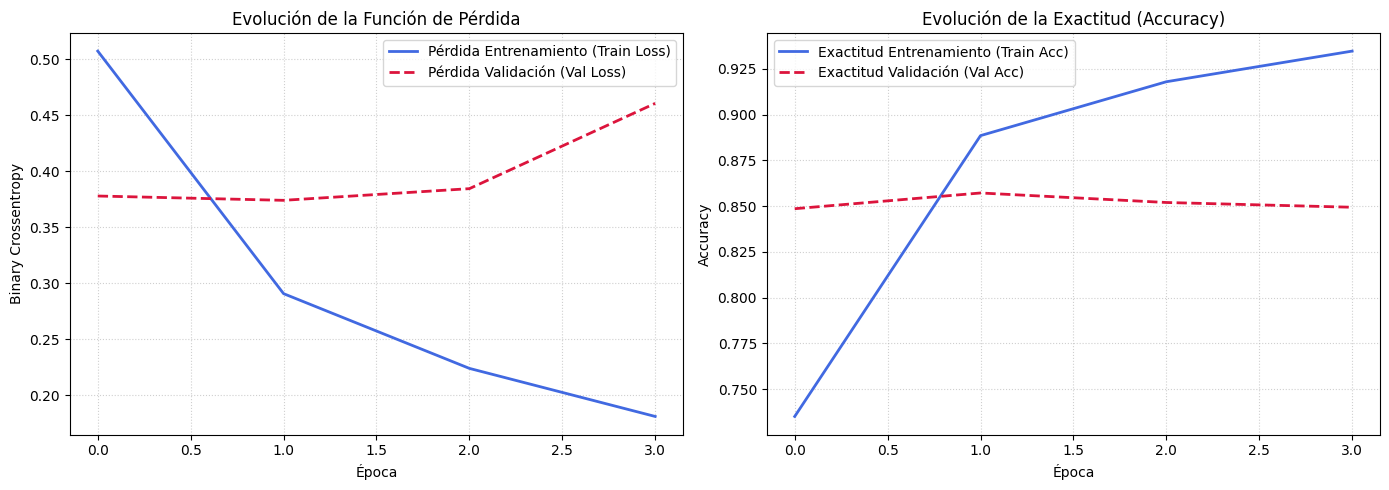

In [8]:
# Gráficas de evolución de Loss y Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica de Pérdida (Loss)
axes[0].plot(history.history['loss'], label='Pérdida Entrenamiento (Train Loss)', color='royalblue', lw=2)
axes[0].plot(history.history['val_loss'], label='Pérdida Validación (Val Loss)', color='crimson', lw=2, linestyle='--')
axes[0].set_title('Evolución de la Función de Pérdida', fontsize=12)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Binary Crossentropy')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Gráfica de Exactitud (Accuracy)
axes[1].plot(history.history['accuracy'], label='Exactitud Entrenamiento (Train Acc)', color='royalblue', lw=2)
axes[1].plot(history.history['val_accuracy'], label='Exactitud Validación (Val Acc)', color='crimson', lw=2, linestyle='--')
axes[1].set_title('Evolución de la Exactitud (Accuracy)', fontsize=12)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Evaluando sobre el conjunto de prueba...
196/196 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step
      MÉTRICAS EN CONJUNTO DE PRUEBA (TEST)     
Accuracy: 0.8486 (84.86%)

--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

Negativa (0)       0.87      0.83      0.84     12500
Positiva (1)       0.83      0.87      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000



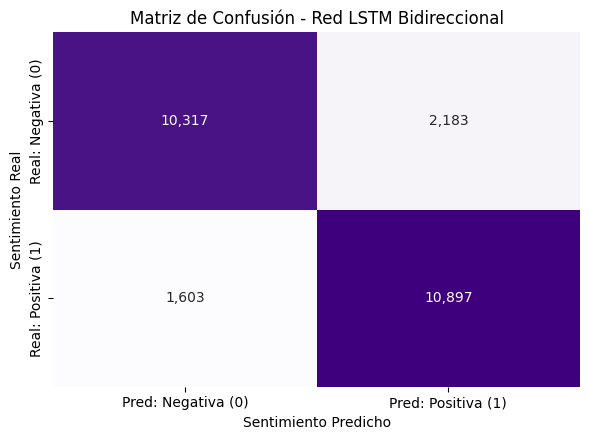

In [9]:
# 1. Cargar el modelo guardado para verificar su correcta persistencia
modelo_eval = tf.keras.models.load_model('models/modelo_sentimientos_lstm.keras')

# 2. Generar predicciones sobre los 25,000 datos de prueba nunca antes vistos
print("Evaluando sobre el conjunto de prueba...")
y_pred_probs = modelo_eval.predict(X_test_pad, batch_size=128)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 3. Métricas obligatorias
acc = accuracy_score(y_test, y_pred)
print("="*48)
print("      MÉTRICAS EN CONJUNTO DE PRUEBA (TEST)     ")
print("="*48)
print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
print("\n--- Reporte de Clasificación Detallado ---")
print(classification_report(y_test, y_pred, target_names=['Negativa (0)', 'Positiva (1)']))

# 4. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm, annot=True, fmt=',d', cmap='Purples', cbar=False,
    xticklabels=['Pred: Negativa (0)', 'Pred: Positiva (1)'],
    yticklabels=['Real: Negativa (0)', 'Real: Positiva (1)']
)
plt.title('Matriz de Confusión - Red LSTM Bidireccional', fontsize=12)
plt.ylabel('Sentimiento Real', fontsize=10)
plt.xlabel('Sentimiento Predicho', fontsize=10)
plt.tight_layout()
plt.show()

In [10]:
# Función para preprocesar texto crudo igual a como lo espera la red
def predict_review_sentiment(text, model, word_dict, max_len=200):
    # Limpieza básica: minúsculas y remoción de caracteres especiales
    tokens = text.lower().replace('<br />', ' ').replace('.', ' ').replace(',', ' ').split()

    # Mapeo a identificadores numéricos (IMDb reserva 0=pad, 1=start, 2=oov, 3=unused)
    # Por convención del dataset, los índices de palabras tienen un desfase de 3
    encoded = []
    for token in tokens:
        idx = word_dict.get(token)
        if idx is not None and (idx + 3) < 10000:
            encoded.append(idx + 3)
        else:
            encoded.append(2)  # 2 representa 'out of vocabulary' (palabra desconocida)

    # Relleno de secuencias (padding)
    padded = pad_sequences([encoded], maxlen=max_len, padding='post', truncating='post')

    # Inferencia
    prob = model.predict(padded, verbose=0)[0][0]
    sentiment = "Positiva" if prob >= 0.5 else "Negativa"
    confidence = prob if prob >= 0.5 else (1 - prob)
    return sentiment, confidence, prob

# 10 reseñas variadas de prueba
sample_reviews = [
    "This movie was an absolute masterpiece with brilliant acting and stunning visuals.",
    "A total waste of time. The plot was completely incoherent and boring.",
    "I genuinely enjoyed the character development and the emotional soundtrack.",
    "Terrible direction, awful dialogue, and zero chemistry between the leads.",
    "One of the best cinematic experiences I have had this year. Highly recommended!",
    "Predictable story, bad editing, and very disappointing performances all around.",
    "A charming, touching story that kept me engaged from beginning to end.",
    "The worst film I have ever seen. Do not bother spending your money on this.",
    "Incredible practical effects and outstanding performances make this a must-watch.",
    "The pacing was painfully slow and none of the jokes landed well."
]

resultados = []
for i, review in enumerate(sample_reviews, 1):
    sent, conf, raw_p = predict_review_sentiment(review, modelo_eval, word_to_index_filtered)
    resultados.append({
        "Prueba": f"#{i}",
        "Reseña": review[:60] + "...",
        "Predicción": sent,
        "Confianza": f"{conf*100:.2f}%",
        "Probabilidad Cruda": f"{raw_p:.4f}"
    })

df_pruebas = pd.DataFrame(resultados)
print("=== 10 PREDICCIONES DE PRUEBA REALIZADAS ===")
df_pruebas

=== 10 PREDICCIONES DE PRUEBA REALIZADAS ===


,Prueba,Reseña,Predicción,Confianza,Probabilidad Cruda
0,#1,This movie was an absolute masterpiece with br...,Positiva,93.13%,0.9313
1,#2,A total waste of time. The plot was completely...,Negativa,98.27%,0.0173
2,#3,I genuinely enjoyed the character development ...,Positiva,84.98%,0.8498
3,#4,"Terrible direction, awful dialogue, and zero c...",Negativa,97.70%,0.0230
4,#5,One of the best cinematic experiences I have h...,Positiva,76.38%,0.7638
5,#6,"Predictable story, bad editing, and very disap...",Negativa,96.22%,0.0378
6,#7,"A charming, touching story that kept me engage...",Positiva,87.85%,0.8785
7,#8,The worst film I have ever seen. Do not bother...,Negativa,97.51%,0.0249
8,#9,Incredible practical effects and outstanding p...,Positiva,84.02%,0.8402
9,#10,The pacing was painfully slow and none of the ...,Negativa,94.18%,0.0582


In [11]:
from google.colab import files

print("Descargando modelo entrenado...")
files.download('models/modelo_sentimientos_lstm.keras')

print("Descargando archivo de vocabulario...")
files.download('models/word_index.json')

Descargando modelo entrenado...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descargando archivo de vocabulario...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>